# Energy vs. Runtime


- **X:** Real-Time Factor = tempo di esecuzione / durata della registrazione (più basso è meglio).
- **Y:** energia CPU + GPU per secondo di registrazione (più basso è meglio).

Modificare `RESULTS_DIR` nella prima cella solo se i risultati si trovano in un altro percorso.

In [1]:
from pathlib import Path
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter
import pandas as pd
import matplotlib.pyplot as plt


# Stessa sessione usata nei notebook originali
RESULTS_DIR = Path("/data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk")
TABLE = RESULTS_DIR / "tables/energy_runtime_by_sample.csv"
if not TABLE.exists():
    raise FileNotFoundError(f"File non trovato: {TABLE}. Controlla RESULTS_DIR.")

df = pd.read_csv(TABLE)
df = df[~((df["dataset"] == "dhp19") & df["sample_id"].isin(["D09", "D10"]))]

# Stesse normalizzazioni dei notebook originali (rapporto tra somme)
summary = df.groupby(["dataset", "model"], as_index=False).agg(
    energy_j=("energy_j", "sum"),
    wall_s=("sequence_wall_seconds", "sum"),
    input_s=("input_span_s", "sum"),
)
summary["rtf"] = summary["wall_s"] / summary["input_s"]
summary["energy_per_input_s"] = summary["energy_j"] / summary["input_s"]


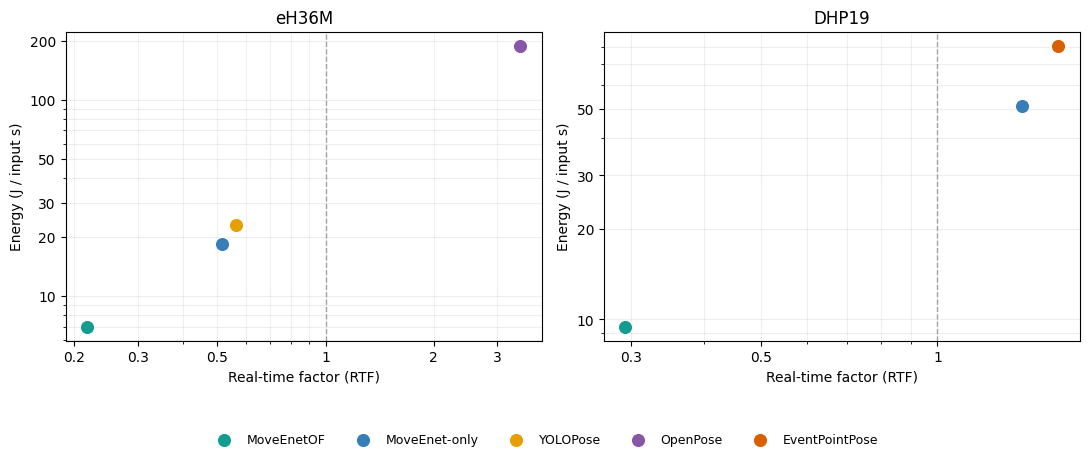

Figura salvata in: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk/figures


In [2]:
# Colori uguali nei due dataset
models = {
    "moveenetofk": ("MoveEnetOF", "#159C91"),
    "movenet": ("MoveEnet-only", "#377EB8"),
    "yolo": ("YOLOPose", "#E69F00"),
    "openpose": ("OpenPose", "#8856A7"),
    "eventpointpose": ("EventPointPose", "#D95F02"),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
legend = {}

for ax, dataset, title in zip(axes, ["h36m", "dhp19"], ["eH36M", "DHP19"]):
    data = summary[summary["dataset"] == dataset]
    for model, (name, color) in models.items():
        point = data[data["model"] == model]
        if point.empty:
            continue
        dot = ax.scatter(point["rtf"].iloc[0], point["energy_per_input_s"].iloc[0],
                         s=105, color=color, edgecolor="white", linewidth=0.8, zorder=3)
        legend[name] = dot

    ax.axvline(1, color="gray", linestyle="--", linewidth=1, alpha=0.7)
    ax.set(xscale="log", yscale="log", title=title,
           xlabel="Real-time factor (RTF)", ylabel="Energy (J / input s)")
    ax.grid(True, which="both", alpha=0.2)

for ax in axes:
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(LogLocator(base=10, subs=(1, 2, 3, 5)))
        axis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
        axis.set_minor_formatter(NullFormatter())

    ax.tick_params(axis="both", labelsize=10)


fig.legend(legend.values(), legend.keys(), loc="lower center",
           ncol=5, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.12, 1, 1))

output = RESULTS_DIR / "figures"
output.mkdir(parents=True, exist_ok=True)
fig.savefig(output / "energy_vs_runtime.png", dpi=300, bbox_inches="tight")
fig.savefig(output / "energy_vs_runtime.svg", bbox_inches="tight")
plt.show()
print("Figura salvata in:", output)


/tmp/ipykernel_403405/2906245532.py:28: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(left=0)
/tmp/ipykernel_403405/2906245532.py:29: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(bottom=0)


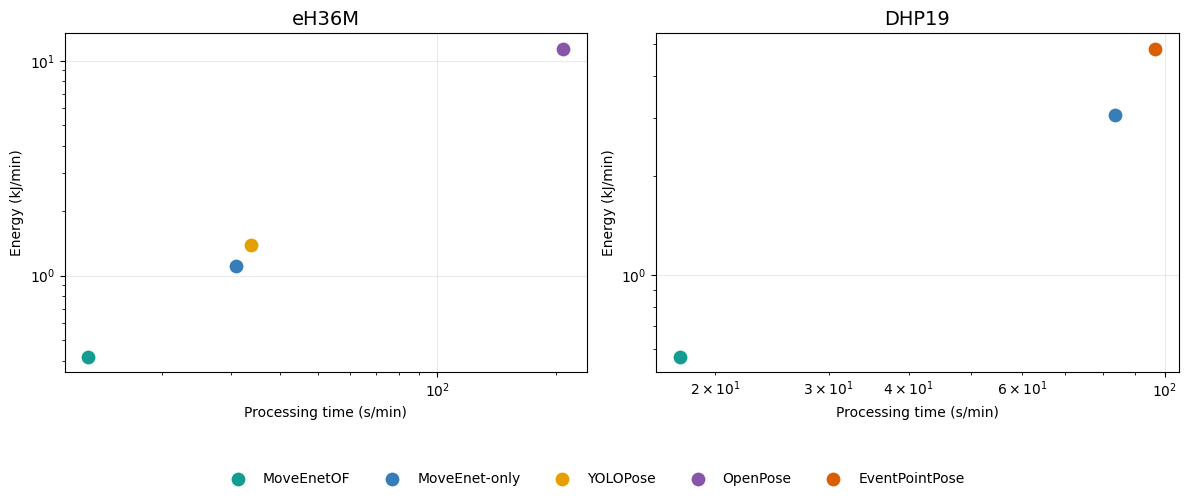

In [3]:
# Energy vs Processing Time - Linear scale

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
legend = {}

for ax, dataset, title in zip(axes, ["h36m", "dhp19"], ["eH36M", "DHP19"]):

    data = summary[summary["dataset"] == dataset]

    for model, (name, color) in models.items():
        point = data[data["model"] == model]
        if point.empty:
            continue

        # Normalize to one minute of input recording
        time = point["rtf"].iloc[0] * 60            # seconds
        energy = point["energy_per_input_s"].iloc[0] * 60 / 1000  # kJ

        dot = ax.scatter(time, energy, s=120, color=color,
                         edgecolor="white", linewidth=1, zorder=3)
        legend[name] = dot

    ax.set_title(title, fontsize=14)
    ax.set(xscale="log", yscale="log", xlabel="Processing time (s/min)", ylabel="Energy (kJ/min)")
    # ax.set_xlabel("Processing time (s/min)", fontsize=12)
    # ax.set_ylabel("Energy (kJ/min)", fontsize=12)

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.25)
    ax.set_axisbelow(True)

fig.legend(legend.values(), legend.keys(),
           loc="lower center", ncol=5, frameon=False)

fig.tight_layout(rect=(0, 0.12, 1, 1))

fig.savefig(output / "energy_vs_runtime_linear.svg", bbox_inches="tight")
fig.savefig(output / "energy_vs_runtime_linear.png", dpi=300, bbox_inches="tight")

plt.show()
